# Multivariate Multi-Horizon Time Series Forecasting Harga Bitcoin

Proyek ini memprediksi nilai penutupan (`Close`) Bitcoin **24 jam ke depan sekaligus** (multi-step) dari beberapa fitur sekaligus (multivariate). Dua keluarga model dibangun dan dilatih dengan *custom training loop* (`tf.GradientTape`):

1. **LSTM baseline**: membaca window 48 jam dan memprediksi 24 langkah sekaligus.
2. **Seq2Seq LSTM** (encoder-decoder) dengan *teacher forcing* saat training dan *autoregressive* saat inferensi.

Komponen kustom yang dibuat dari nol: `CustomDense`, `CustomMultiHeadAttention`, `CustomLayerNormalization`, `CustomELU`, `CustomDropout`, loss MAE, loss MAE berbobot horizon, *early stopping*, dan *reduce learning rate on plateau*.

**Daftar isi**
1. Persiapan data dan EDA (heatmap korelasi, feature engineering, dekomposisi, ACF/PACF)
2. Pipeline `tf.data` (train / validation / test) dan normalisasi tanpa data leakage
3. Layer, model, loss, dan callback kustom
4. Training (custom training loop) dan evaluasi
5. Visualisasi prediksi dan tabel perbandingan
6. Penyimpanan model dan kesimpulan

In [1]:
import os, random, math, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import pacf
import tensorflow as tf
import keras
from keras import layers

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

HORIZON = 24      # jumlah langkah (jam) yang diprediksi
BATCH_SIZE = 256
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

TensorFlow: 2.21.0 | Keras: 3.15.1


## 1. Memuat Data

Dataset: *Multivariate Crypto Data Hourly since 2017 to 2023*, subset **Bitcoin** (diunduh dari tautan yang disediakan pada materi). Setiap baris adalah satu jam; kolom `Close` adalah target prediksi.

In [2]:
CSV_URL = "https://drive.google.com/uc?export=download&id=1hpsqSpfjdqIZWqwd259klQSeaNSe5Trr"
try:
    df_raw = pd.read_csv(CSV_URL)
except Exception as err:  # cadangan jika Google Drive tidak dapat diakses
    print("Unduhan gagal:", err, "-> memakai salinan lokal data_raw.csv")
    df_raw = pd.read_csv("data_raw.csv")

print("Ukuran data:", df_raw.shape)
df_raw.head()

Ukuran data: (53150, 7)


,Date,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO
0,2017-09-21 09:00:00.000,3860.00,74434.891166,49.192454,-48.279697,88.054720,2.495591
1,2017-09-21 10:00:00.000,3871.48,44687.318944,49.233202,-47.780476,87.996283,2.616710
2,2017-09-21 11:00:00.000,3864.95,80546.171672,49.210685,-47.308061,87.897128,2.532239
3,2017-09-21 12:00:00.000,3858.08,90331.531390,49.186948,-46.863233,87.720856,2.447245
4,2017-09-21 13:00:00.000,3856.67,103405.818040,49.182064,-46.425379,87.578086,2.424654


In [3]:
df_raw.info()
df_raw.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 53150 entries, 0 to 53149
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         53150 non-null  str    
 1   Close        53150 non-null  float64
 2   Volume USDT  53150 non-null  float64
 3   RSI          53150 non-null  float64
 4   MACD_Hist    53150 non-null  float64
 5   ATR          53150 non-null  float64
 6   KAMAO        53150 non-null  float64
dtypes: float64(6), str(1)
memory usage: 2.8 MB


,count,mean,std,min,25%,50%,75%,max
Close,53150.0,2.059536e+04,1.582230e+04,3172.050000,7.976915e+03,1.387810e+04,2.964672e+04,6.863369e+04
Volume USDT,53150.0,6.919215e+07,1.059041e+08,0.000000,1.012558e+07,2.766119e+07,8.944278e+07,3.005634e+09
RSI,53150.0,5.040360e+01,3.210682e+00,35.178834,4.829420e+01,5.003848e+01,5.240627e+01,6.465711e+01
MACD_Hist,53150.0,5.282720e-01,3.532932e+02,-1885.690630,-1.156016e+02,1.015442e+01,1.223675e+02,1.430406e+03
ATR,53150.0,2.217333e+02,2.084014e+02,17.436266,7.270249e+01,1.287876e+02,3.256168e+02,1.004531e+03
KAMAO,53150.0,2.297622e-01,5.168655e+00,-31.767152,-2.717470e+00,-3.274670e-02,3.162442e+00,3.974030e+01


### Pembersihan Data

Data diurutkan berdasarkan waktu, lalu dipastikan tidak ada duplikasi dan jam yang hilang. Jam yang hilang (sedikit) diisi dengan interpolasi berbasis waktu agar setiap langkah pada window benar-benar berjarak satu jam.

In [4]:
df = df_raw.rename(columns={"Volume USDT": "Volume_USDT"}).copy()
df["Date"] = pd.to_datetime(df["Date"], format="mixed")
df = df.sort_values("Date").drop_duplicates("Date").set_index("Date")
df.index = df.index.floor("h")

full_index = pd.date_range(df.index.min(), df.index.max(), freq="h")
n_missing = len(full_index) - len(df)
print(f"Jam yang hilang dari rentang data: {n_missing} dari {len(full_index)} ({n_missing / len(full_index):.2%})")
print("Nilai kosong per kolom:\n", df.isna().sum().to_string())

# Jam yang hilang diisi dengan interpolasi berbasis waktu agar deret tetap per jam
df = df.reindex(full_index).interpolate(method="time")
df.index.name = "Date"
print("Setelah reindex per jam:", df.shape, "| sisa NaN:", int(df.isna().sum().sum()))

Jam yang hilang dari rentang data: 121 dari 53271 (0.23%)
Nilai kosong per kolom:
 Close          0
Volume_USDT    0
RSI            0
MACD_Hist      0
ATR            0
KAMAO          0
Setelah reindex per jam: (53271, 6) | sisa NaN: 0


## 2. Exploratory Data Analysis

Harga Bitcoin memiliki tren yang kuat dan volatil (puncak sekitar 68 ribu USD pada akhir 2021, lalu turun tajam pada 2022). Karena itu pembagian data dilakukan secara kronologis, bukan acak.

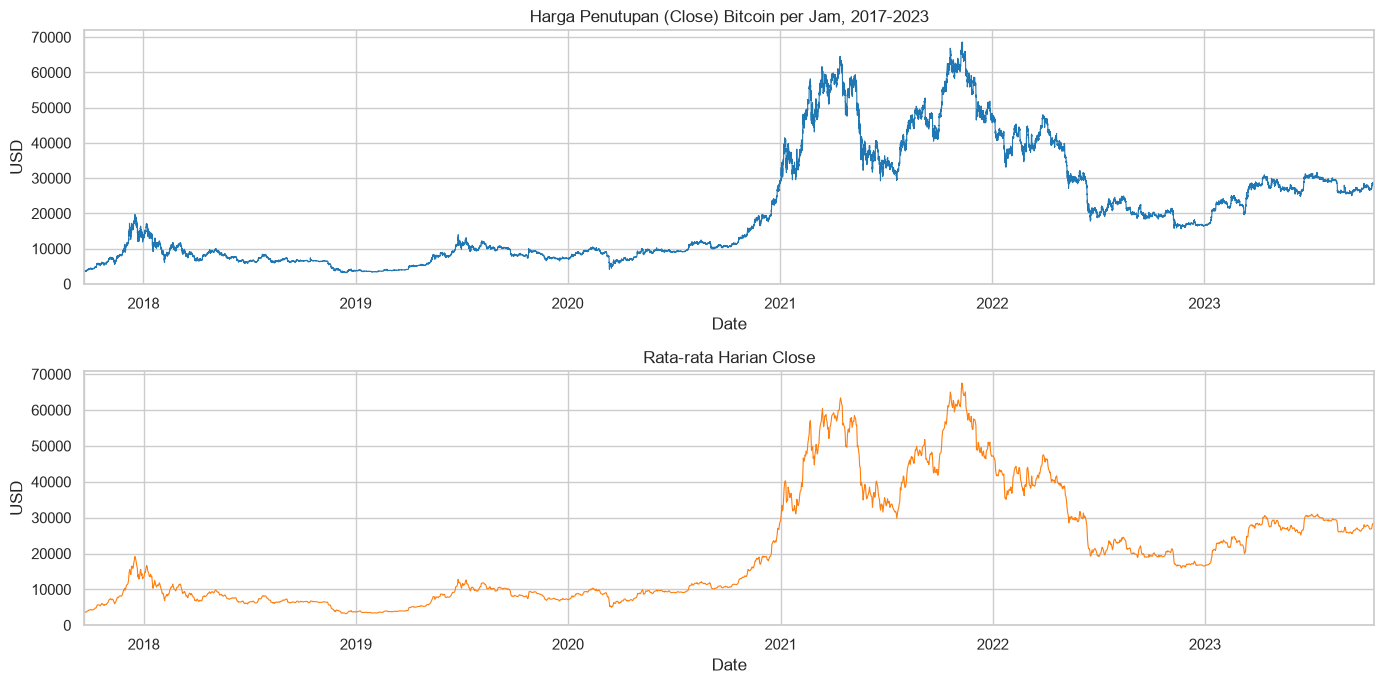

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
df["Close"].plot(ax=axes[0], color="tab:blue", lw=0.8)
axes[0].set_title("Harga Penutupan (Close) Bitcoin per Jam, 2017-2023")
axes[0].set_ylabel("USD")
df["Close"].resample("D").mean().plot(ax=axes[1], color="tab:orange", lw=0.8)
axes[1].set_title("Rata-rata Harian Close")
axes[1].set_ylabel("USD")
plt.tight_layout()
plt.show()

### Pemilihan Fitur dan Korelasi

Semua 6 kolom numerik dipakai sebagai input (syarat minimal 3 fitur): `Close`, `Volume_USDT`, `RSI`, `MACD_Hist`, `ATR`, dan `KAMAO`. Heatmap korelasi di bawah menunjukkan `Close` berkorelasi kuat dengan `ATR` (rentang harga yang lebih tinggi ikut menaikkan volatilitas absolut) dan cukup dengan `Volume_USDT`, sedangkan indikator momentum (`RSI`, `MACD_Hist`, `KAMAO`) saling berkorelasi tetapi hampir tidak berkorelasi dengan level harga; ketiganya tetap berguna sebagai informasi arah/momentum.

Fitur input (dasar): ['Close', 'Volume_USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO'] -> 6 fitur


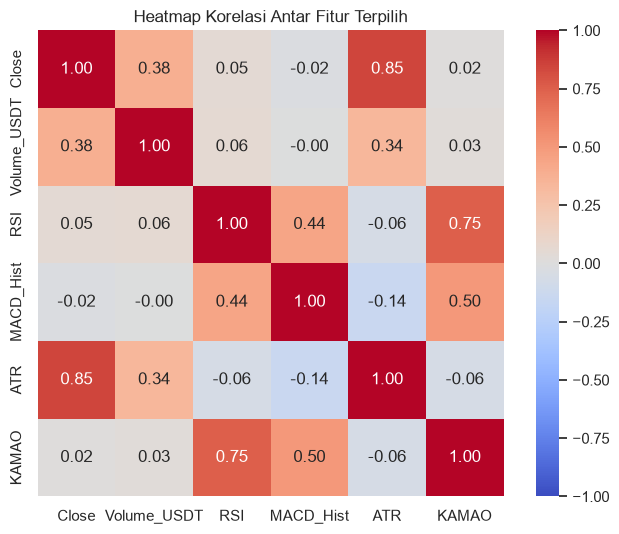

In [6]:
BASE_FEATURES = ["Close", "Volume_USDT", "RSI", "MACD_Hist", "ATR", "KAMAO"]
print("Fitur input (dasar):", BASE_FEATURES, f"-> {len(BASE_FEATURES)} fitur")

plt.figure(figsize=(7, 5.5))
sns.heatmap(df[BASE_FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Heatmap Korelasi Antar Fitur Terpilih")
plt.tight_layout()
plt.show()

### Feature Engineering: Rolling Statistic

Ditambahkan tiga fitur *rolling statistic* dengan jendela 24 jam: rata-rata dan simpangan baku `Close`, serta rata-rata `Volume_USDT`. Jendela hanya melihat ke belakang (jam saat ini dan 23 jam sebelumnya), sehingga tidak ada informasi masa depan yang bocor. 23 baris awal yang belum memiliki jendela penuh dibuang.

Fitur akhir: ['Close', 'Volume_USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO', 'Close_roll_mean_24', 'Close_roll_std_24', 'Volume_roll_mean_24']
Ukuran data: (53248, 9) | 2017-09-22 08:00:00 -> 2023-10-19 23:00:00


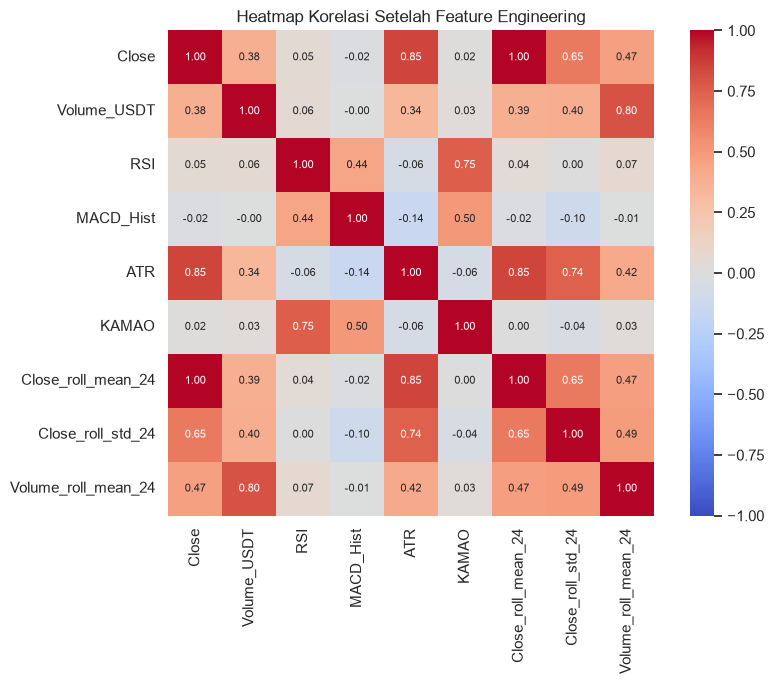

In [7]:
ROLL = 24
data = df[BASE_FEATURES].copy()
# Rolling statistic memakai jendela ke belakang (termasuk jam saat ini), sehingga tidak memakai informasi masa depan
data["Close_roll_mean_24"] = data["Close"].rolling(ROLL).mean()
data["Close_roll_std_24"] = data["Close"].rolling(ROLL).std()
data["Volume_roll_mean_24"] = data["Volume_USDT"].rolling(ROLL).mean()
data = data.dropna()

FEATURES = list(data.columns)
TARGET = "Close"
TARGET_IDX = FEATURES.index(TARGET)
N_FEATURES = len(FEATURES)
print("Fitur akhir:", FEATURES)
print("Ukuran data:", data.shape, "|", data.index.min(), "->", data.index.max())

plt.figure(figsize=(9, 7))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, annot_kws={"size": 8})
plt.title("Heatmap Korelasi Setelah Feature Engineering")
plt.tight_layout()
plt.show()

### Pembagian Data Train / Validation / Test

Pembagian kronologis 70% / 15% / 15% (tanpa pengacakan) agar data uji selalu berada setelah data latih dan validasi.

Train     :  37273 baris | 2017-09-22 08:00:00 -> 2021-12-23 08:00:00 | Close 3,172 - 68,634
Validation:   7987 baris | 2021-12-23 09:00:00 -> 2022-11-21 03:00:00 | Close 15,751 - 51,853
Test      :   7988 baris | 2022-11-21 04:00:00 -> 2023-10-19 23:00:00 | Close 15,650 - 31,606


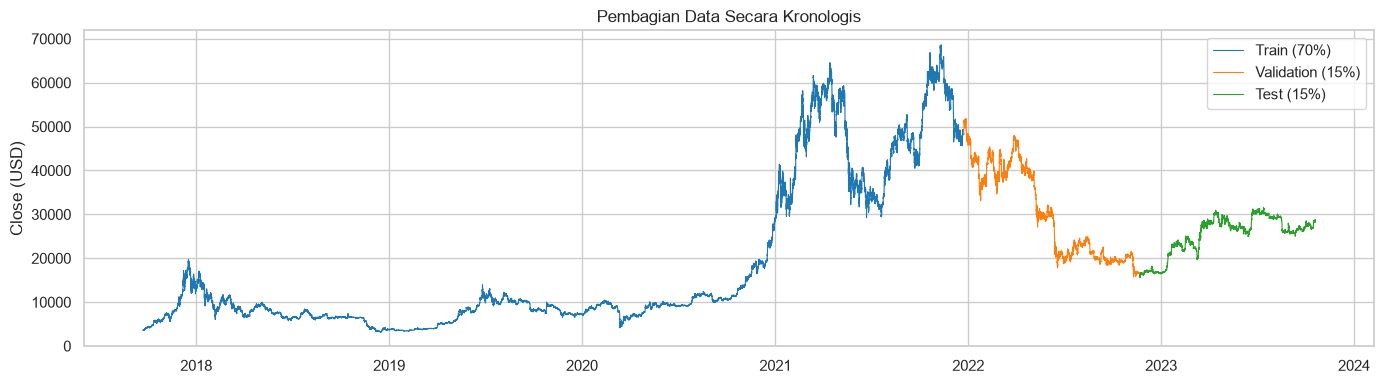

In [8]:
n = len(data)
n_train, n_val = int(n * 0.70), int(n * 0.15)
train_df = data.iloc[:n_train]
val_df = data.iloc[n_train:n_train + n_val]
test_df = data.iloc[n_train + n_val:]

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:<10}: {len(part):>6} baris | {part.index.min()} -> {part.index.max()} | Close {part['Close'].min():,.0f} - {part['Close'].max():,.0f}")

plt.figure(figsize=(14, 4))
for part, label, color in [(train_df, "Train (70%)", "tab:blue"), (val_df, "Validation (15%)", "tab:orange"), (test_df, "Test (15%)", "tab:green")]:
    plt.plot(part.index, part["Close"], label=label, color=color, lw=0.8)
plt.title("Pembagian Data Secara Kronologis")
plt.ylabel("Close (USD)")
plt.legend()
plt.tight_layout()
plt.show()

### Analisis Dekomposisi

Dekomposisi aditif (`trend + seasonal + residual`) dengan periode 24 jam dilakukan pada **data latih** untuk target `Close`. Trend menangkap hampir seluruh variasi harga, komponen musiman harian sangat kecil (puluhan USD dibanding harga puluhan ribu USD), dan residual bersifat acak dengan amplitudo kecil. Artinya harga berperilaku mirip *random walk* dengan tren: pola harian ada, tetapi lemah.

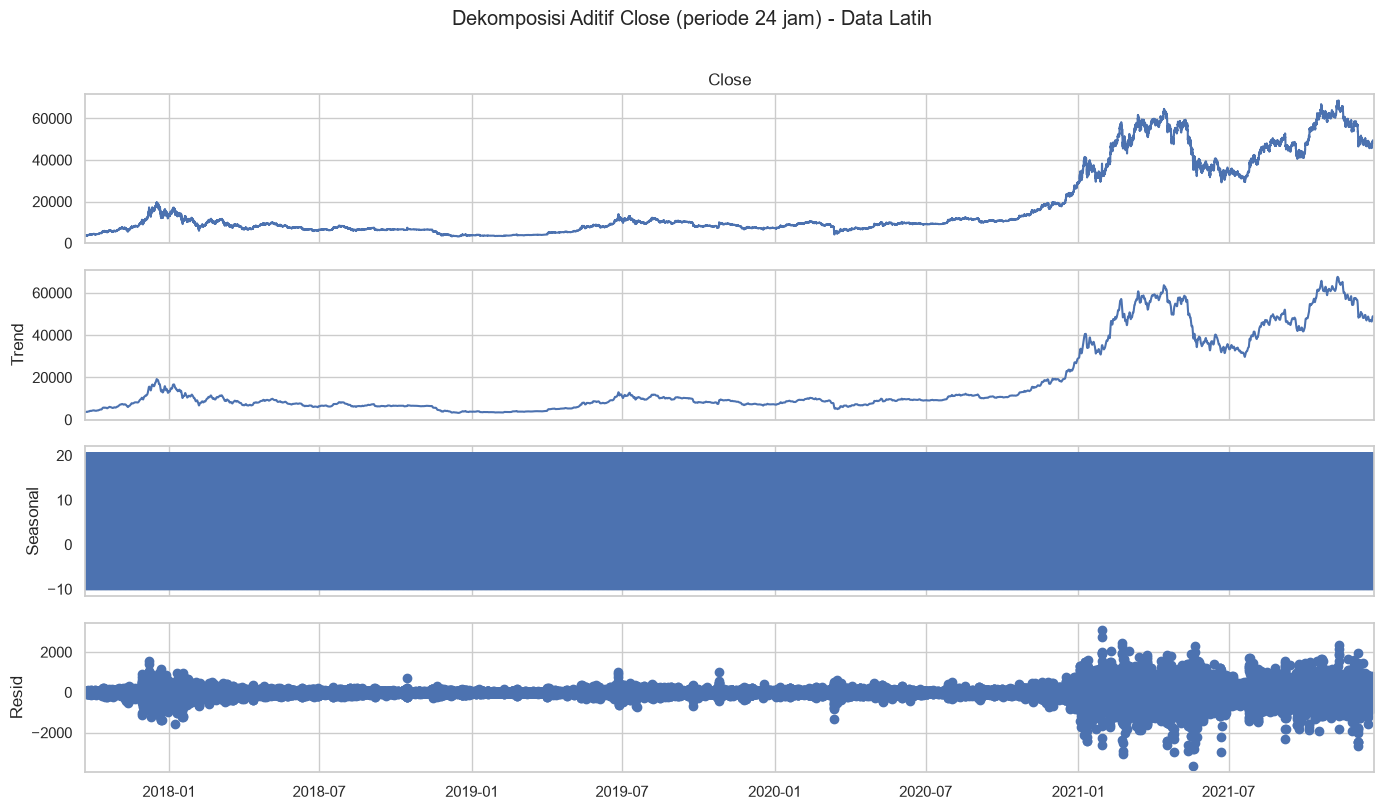

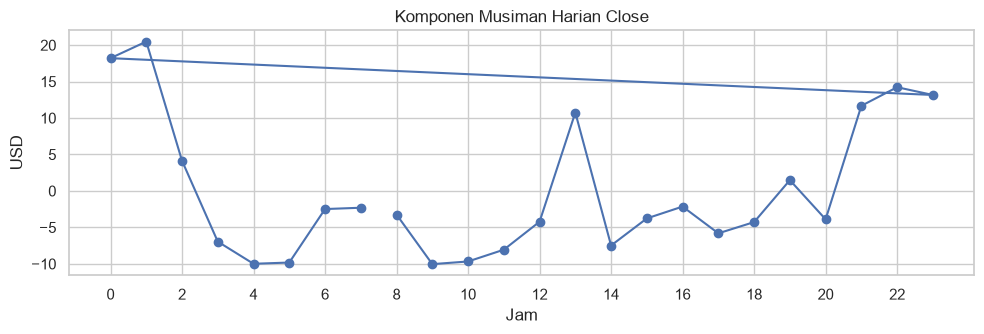

Amplitudo musiman: 30.5 USD | porsi varians residual terhadap total: 0.0283%


In [9]:
# Dekomposisi aditif dengan periode 24 jam (siklus harian) pada data latih
decomp = seasonal_decompose(train_df["Close"], model="additive", period=24)
fig = decomp.plot()
fig.set_size_inches(14, 8)
fig.suptitle("Dekomposisi Aditif Close (periode 24 jam) - Data Latih", y=1.01)
plt.tight_layout()
plt.show()

# Pola musiman harian (24 jam pertama) diperbesar
seasonal_daily = decomp.seasonal.iloc[:24]
plt.figure(figsize=(10, 3.5))
plt.plot(seasonal_daily.index.hour, seasonal_daily.values, marker="o")
plt.title("Komponen Musiman Harian Close")
plt.xlabel("Jam")
plt.ylabel("USD")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

resid_share = decomp.resid.var() / train_df["Close"].var()
print(f"Amplitudo musiman: {seasonal_daily.max() - seasonal_daily.min():.1f} USD | porsi varians residual terhadap total: {resid_share:.4%}")

### Analisis Lag (ACF dan PACF) untuk Menentukan Window Size

ACF `Close` (level) turun sangat lambat karena deret tidak stasioner, sehingga PACF dan ACF pada **selisih** `Close` lebih informatif. Pada PACF selisih terdapat lag signifikan di sekitar **24-25 jam** dan **48-49 jam**, yaitu pola siklus harian. Karena itu window size dipilih **48 jam** agar mencakup dua siklus harian penuh; lag-lag signifikan di atas itu bernilai kecil dan tidak menambah informasi yang berarti.

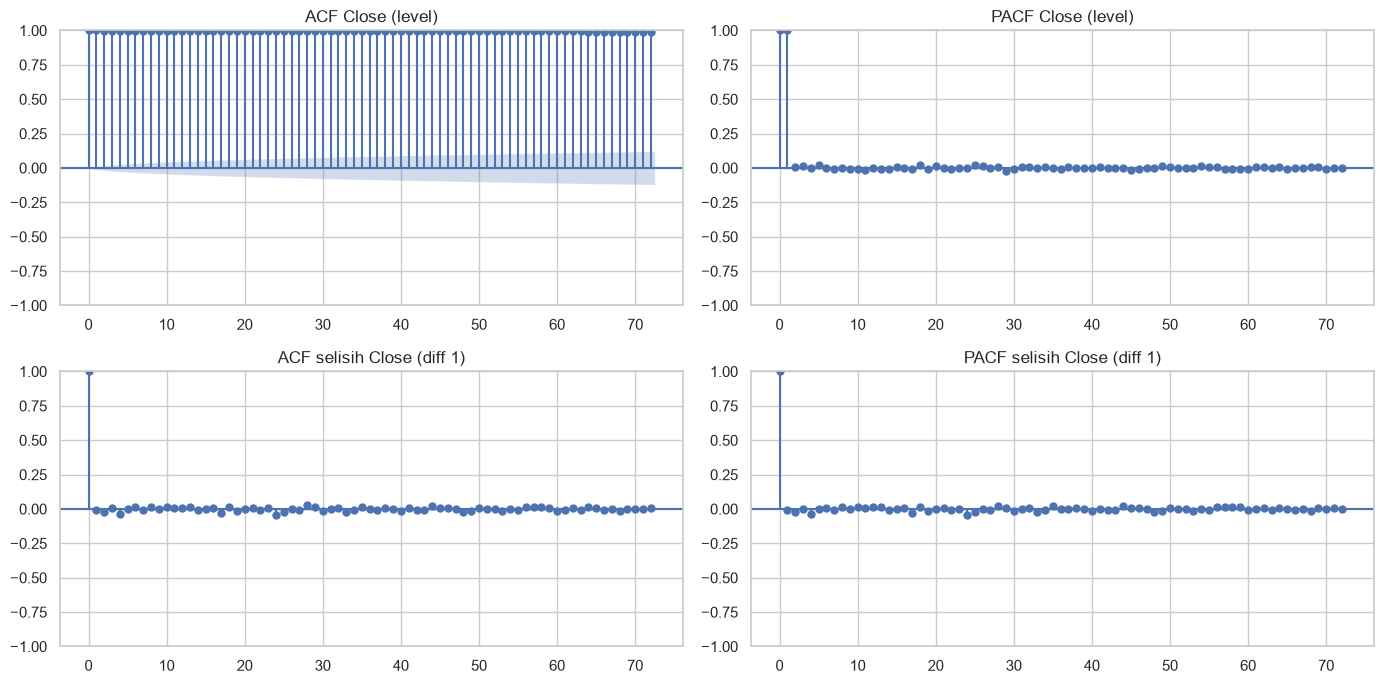

Lag PACF signifikan pada selisih Close: [2, 4, 6, 8, 10, 12, 13, 17, 18, 19, 24, 25, 28, 30, 33, 35, 40, 44, 48, 49, 53, 56, 57, 58, 59, 64, 68]


In [10]:
close_train = train_df["Close"]
close_diff = close_train.diff().dropna()
NLAGS = 72

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(close_train, lags=NLAGS, ax=axes[0, 0], title="ACF Close (level)")
plot_pacf(close_train, lags=NLAGS, ax=axes[0, 1], method="ywm", title="PACF Close (level)")
plot_acf(close_diff, lags=NLAGS, ax=axes[1, 0], title="ACF selisih Close (diff 1)")
plot_pacf(close_diff, lags=NLAGS, ax=axes[1, 1], method="ywm", title="PACF selisih Close (diff 1)")
plt.tight_layout()
plt.show()

pacf_vals = pacf(close_diff, nlags=NLAGS, method="ywm")
conf = 1.96 / np.sqrt(len(close_diff))
sig_lags = [k for k in range(1, NLAGS + 1) if abs(pacf_vals[k]) > conf]
print("Lag PACF signifikan pada selisih Close:", sig_lags)

In [11]:
# Lag signifikan menumpuk di sekitar 24-25 dan 48-49 jam (siklus harian); window dibuat mencakup dua siklus harian
WINDOW = 48
print("Lag sekitar 24 jam :", [l for l in sig_lags if 22 <= l <= 26])
print("Lag sekitar 48 jam :", [l for l in sig_lags if 46 <= l <= 50])
assert any(l in sig_lags for l in (24, 25)) and any(l in sig_lags for l in (48, 49))
print(f"WINDOW = {WINDOW} jam | HORIZON = {HORIZON} jam")

Lag sekitar 24 jam : [24, 25]
Lag sekitar 48 jam : [48, 49]
WINDOW = 48 jam | HORIZON = 24 jam


## 3. Normalisasi dan Pipeline `tf.data`

### Normalisasi tanpa Data Leakage

Setiap kolom dinormalisasi dengan Min-Max ke rentang [0, 1], dan **parameter (min dan max) dihitung hanya dari data latih**. Data validasi dan test hanya di-*transform* memakai parameter data latih. Nilai di luar [0, 1] pada validasi/test (misalnya fitur `Volume`) adalah hal yang wajar dan menandakan tidak ada kebocoran.

In [12]:
# Normalisasi Min-Max per kolom; statistik dihitung HANYA dari data latih (tanpa data leakage)
scaler = MinMaxScaler()
scaler.fit(train_df[FEATURES])
train_s = scaler.transform(train_df[FEATURES]).astype("float32")
val_s = scaler.transform(val_df[FEATURES]).astype("float32")
test_s = scaler.transform(test_df[FEATURES]).astype("float32")

close_min, close_max = scaler.data_min_[TARGET_IDX], scaler.data_max_[TARGET_IDX]
def inverse_close(x):
    return np.asarray(x) * (close_max - close_min) + close_min

print("Rentang train (scaled):", train_s.min().round(3), "-", train_s.max().round(3))
print("Rentang val   (scaled):", val_s.min().round(3), "-", val_s.max().round(3))
print("Rentang test  (scaled):", test_s.min().round(3), "-", test_s.max().round(3))

Rentang train (scaled): 0.0 - 1.0
Rentang val   (scaled): 0.004 - 1.985
Rentang test  (scaled): 0.0 - 1.333


### Pipeline `tf.data.Dataset`

Setiap sampel adalah window 48 jam (9 fitur) dengan target 24 nilai `Close` berikutnya. Untuk Seq2Seq, input decoder berisi `Close` sebenarnya yang digeser satu langkah (*teacher forcing*): langkah pertama diisi `Close` terakhir pada window, langkah berikutnya diisi nilai aktual langkah sebelumnya. Window dibentuk di dalam masing-masing bagian (train, validation, test) sehingga tidak ada window yang melintasi batas pembagian.

In [13]:
def make_dataset(arr, kind, shuffle=False, batch_size=BATCH_SIZE):
    """tf.data pipeline: jendela (WINDOW) -> target (HORIZON langkah Close).
    kind='baseline' -> (x, y); kind='seq2seq' -> ((x, decoder_input), y) dengan teacher forcing."""
    arr = tf.constant(arr, tf.float32)
    n_win = arr.shape[0] - WINDOW - HORIZON + 1

    def _get(i):
        x = arr[i:i + WINDOW]
        y = arr[i + WINDOW:i + WINDOW + HORIZON, TARGET_IDX]
        if kind == "baseline":
            return x, y
        # decoder input = nilai Close sebenarnya satu langkah sebelumnya (Close terakhir pada window untuk langkah pertama)
        dec = tf.concat([x[-1:, TARGET_IDX], y[:-1]], axis=0)[:, None]
        return (x, dec), y

    ds = tf.data.Dataset.range(n_win)
    if shuffle:
        ds = ds.shuffle(n_win, seed=SEED, reshuffle_each_iteration=True)
    return ds.map(_get, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)

def window_arrays(arr):
    """Versi numpy dari jendela: X (N, WINDOW, F) dan Y (N, HORIZON), dipakai untuk inferensi dan evaluasi."""
    n_win = arr.shape[0] - WINDOW - HORIZON + 1
    idx = np.arange(n_win)[:, None]
    X = arr[idx + np.arange(WINDOW)[None, :]]
    Y = arr[idx + WINDOW + np.arange(HORIZON)[None, :], TARGET_IDX]
    return X, Y

train_base, val_base, test_base = (make_dataset(train_s, "baseline", shuffle=True), make_dataset(val_s, "baseline"), make_dataset(test_s, "baseline"))
train_s2s, val_s2s, test_s2s = (make_dataset(train_s, "seq2seq", shuffle=True), make_dataset(val_s, "seq2seq"), make_dataset(test_s, "seq2seq"))

X_test, Y_test = window_arrays(test_s)
print("Jumlah window  train/val/test:", len(train_s) - WINDOW - HORIZON + 1, len(val_s) - WINDOW - HORIZON + 1, len(test_s) - WINDOW - HORIZON + 1)
(xb, yb) = next(iter(train_base))
print("Baseline  : x", xb.shape, "y", yb.shape)
((xb, db), yb) = next(iter(train_s2s))
print("Seq2Seq   : x", xb.shape, "decoder", db.shape, "y", yb.shape)

Jumlah window  train/val/test: 37202 7916 7917
Baseline  : x (256, 48, 9) y (256, 24)
Seq2Seq   : x (256, 48, 9) decoder (256, 24, 1) y (256, 24)


## 4. Layer Kustom

Beberapa layer dibuat ulang dari nol dengan `keras.layers.Layer`, diberi `get_config`, dan didaftarkan agar model dapat disimpan dan dimuat ulang dalam format `.keras`:

| Layer | Keterangan |
|---|---|
| `CustomDense` | `y = act(xW + b)`, mendukung input 2D/3D |
| `CustomMultiHeadAttention` | Scaled dot-product attention multi-head, proyeksi Q/K/V/output memakai `CustomDense` |
| `CustomLayerNormalization` | Normalisasi sumbu fitur + `gamma`/`beta` |
| `CustomELU` | Fungsi aktivasi ELU |
| `CustomDropout` | Inverted dropout (aktif hanya saat training) |
| `AddLastClose`, `AddPreviousClose` | Skip connection ke nilai `Close` terakhir/langkah sebelumnya, sehingga model mempelajari **perubahan** harga (delta) dan bukan level harga mentah |

In [14]:
register = keras.saving.register_keras_serializable(package="dltm")

@register
class CustomDense(layers.Layer):
    """Layer Dense dibuat dari nol: y = activation(x @ W + b). Mendukung input 2D maupun 3D."""
    def __init__(self, units, activation=None, kernel_initializer="glorot_uniform", **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = keras.activations.get(activation)
        self.kernel_initializer = keras.initializers.get(kernel_initializer)

    def build(self, input_shape):
        self.kernel = self.add_weight(name="kernel", shape=(input_shape[-1], self.units), initializer=self.kernel_initializer)
        self.bias = self.add_weight(name="bias", shape=(self.units,), initializer="zeros")

    def call(self, x):
        y = tf.tensordot(x, self.kernel, axes=[[-1], [0]]) + self.bias
        return self.activation(y) if self.activation is not None else y

    def get_config(self):
        return {**super().get_config(), "units": self.units, "activation": keras.activations.serialize(self.activation),
                "kernel_initializer": keras.initializers.serialize(self.kernel_initializer)}

@register
class CustomDropout(layers.Layer):
    """Inverted dropout dari nol; hanya aktif saat training."""
    def __init__(self, rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.rate = rate

    def call(self, x, training=False):
        if not training or self.rate == 0.0:
            return x
        keep = 1.0 - self.rate
        mask = tf.cast(tf.random.uniform(tf.shape(x)) < keep, x.dtype)
        return x * mask / keep

    def get_config(self):
        return {**super().get_config(), "rate": self.rate}

@register
class CustomLayerNormalization(layers.Layer):
    """Layer Normalization dari nol (normalisasi pada sumbu fitur terakhir + gamma/beta yang dapat dilatih)."""
    def __init__(self, epsilon=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, input_shape):
        self.gamma = self.add_weight(name="gamma", shape=(input_shape[-1],), initializer="ones")
        self.beta = self.add_weight(name="beta", shape=(input_shape[-1],), initializer="zeros")

    def call(self, x):
        mean, var = tf.nn.moments(x, axes=[-1], keepdims=True)
        return self.gamma * (x - mean) * tf.math.rsqrt(var + self.epsilon) + self.beta

    def get_config(self):
        return {**super().get_config(), "epsilon": self.epsilon}

@register
class CustomELU(layers.Layer):
    """Fungsi aktivasi ELU dari nol: x jika x > 0, alpha * (exp(x) - 1) jika x <= 0."""
    def __init__(self, alpha=1.0, **kwargs):
        super().__init__(**kwargs)
        self.alpha = alpha

    def call(self, x):
        return tf.where(x > 0.0, x, self.alpha * (tf.exp(tf.minimum(x, 0.0)) - 1.0))

    def get_config(self):
        return {**super().get_config(), "alpha": self.alpha}

@register
class CustomMultiHeadAttention(layers.Layer):
    """Multi-Head (scaled dot-product) Attention dari nol, memakai CustomDense untuk proyeksi Q, K, V, dan output."""
    def __init__(self, num_heads, key_dim, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_heads, self.key_dim, self.output_dim = num_heads, key_dim, output_dim
        self.q_proj = CustomDense(num_heads * key_dim, name="q_proj")
        self.k_proj = CustomDense(num_heads * key_dim, name="k_proj")
        self.v_proj = CustomDense(num_heads * key_dim, name="v_proj")
        self.o_proj = CustomDense(output_dim, name="o_proj")

    def build(self, query_shape, value_shape):
        self.q_proj.build(query_shape)
        self.k_proj.build(value_shape)
        self.v_proj.build(value_shape)
        self.o_proj.build((None, None, self.num_heads * self.key_dim))

    def _split_heads(self, x):
        b, t = tf.shape(x)[0], tf.shape(x)[1]
        x = tf.reshape(x, (b, t, self.num_heads, self.key_dim))
        return tf.transpose(x, (0, 2, 1, 3))  # (B, heads, T, key_dim)

    def call(self, query, value):
        q = self._split_heads(self.q_proj(query))
        k = self._split_heads(self.k_proj(value))
        v = self._split_heads(self.v_proj(value))
        scores = tf.matmul(q, k, transpose_b=True) / math.sqrt(self.key_dim)
        weights = tf.nn.softmax(scores, axis=-1)
        context = tf.transpose(tf.matmul(weights, v), (0, 2, 1, 3))  # (B, Tq, heads, key_dim)
        b, tq = tf.shape(context)[0], tf.shape(context)[1]
        context = tf.reshape(context, (b, tq, self.num_heads * self.key_dim))
        return self.o_proj(context)

    def get_config(self):
        return {**super().get_config(), "num_heads": self.num_heads, "key_dim": self.key_dim, "output_dim": self.output_dim}

@register
class LastStep(layers.Layer):
    """Mengambil time step terakhir dari tensor (B, T, D) -> (B, D)."""
    def call(self, x):
        return x[:, -1, :]

@register
class AddLastClose(layers.Layer):
    """Skip connection: prediksi = delta yang dipelajari model + Close terakhir pada window (pendekatan naive)."""
    def call(self, delta, window):
        return delta + window[:, -1:, TARGET_IDX]

@register
class AddPreviousClose(layers.Layer):
    """Skip connection untuk decoder: prediksi_t = delta_t + input decoder_t (Close pada langkah sebelumnya)."""
    def call(self, delta, dec_in):
        return delta + dec_in[:, :, 0]

In [15]:
# Uji singkat: layer kustom harus setara bentuk/perilakunya dengan layer bawaan Keras
t = tf.random.normal((2, 5, 16))
print("CustomDense     :", CustomDense(8)(t).shape)
print("CustomMHA       :", CustomMultiHeadAttention(4, 4, 16)(t, t).shape, "| MHA bawaan:", layers.MultiHeadAttention(4, 4)(t, t).shape)
ln = CustomLayerNormalization()(t)
print("CustomLayerNorm : mean ~", round(float(tf.reduce_mean(ln)), 6), "| std ~", round(float(tf.math.reduce_std(ln)), 4))
probe = tf.constant([-2.0, 0.0, 2.0])
print("CustomELU       :", CustomELU()(probe).numpy(), "| ELU bawaan:", keras.activations.elu(probe).numpy())
print("CustomDropout   : rasio nol (training, rate 0.5) =", round(float(tf.reduce_mean(tf.cast(CustomDropout(0.5)(tf.ones((10000,)), training=True) == 0, tf.float32))), 3))

CustomDense     : (2, 5, 8)
CustomMHA       : (2, 5, 16) | MHA bawaan: (2, 5, 16)
CustomLayerNorm : mean ~ -0.0 | std ~ 1.0
CustomELU       : [-0.86466473  0.          2.        ] | ELU bawaan: [-0.86466473  0.          2.        ]
CustomDropout   : rasio nol (training, rate 0.5) = 0.502


## 5. Arsitektur Model

**LSTM baseline** (`WINDOW x 9` masuk, 24 langkah keluar):

| Varian | Arsitektur |
|---|---|
| `plain` | LSTM(64) -> Dense bawaan Keras |
| `custom_dense` | LSTM(64) -> `CustomDense` |
| `keras_mha` | LSTM(64, seq) -> MHA bawaan Keras (+residual) -> `CustomDense` |
| `custom_mha` | LSTM(64, seq) -> `CustomMHA` (+residual) -> `CustomLayerNorm` -> `CustomDense` -> `CustomELU` -> `CustomDropout` -> `CustomDense` |

**Seq2Seq LSTM** (encoder LSTM menghasilkan *state* untuk decoder LSTM; decoder menerima `Close` langkah sebelumnya):

| Varian | Cara pembangunan |
|---|---|
| Functional | Functional API, decoder -> `CustomDense` |
| Subclass + MHA | Model Subclassing, cross-attention MHA bawaan Keras (decoder sebagai query, keluaran encoder sebagai key/value) |
| Subclass + CustomMHA | Model Subclassing, `CustomMultiHeadAttention` + `CustomLayerNorm` + `CustomDense` + `CustomELU` + `CustomDropout` |

In [16]:
UNITS, HEADS, KEY_DIM, DROPOUT = 64, 4, 16, 0.1

def build_baseline(variant, name):
    """Model LSTM baseline. variant: plain | custom_dense | keras_mha | custom_mha"""
    inp = keras.Input((WINDOW, N_FEATURES), name="encoder_input")
    if variant in ("plain", "custom_dense"):
        h = layers.LSTM(UNITS)(inp)
        out = layers.Dense(HORIZON)(h) if variant == "plain" else CustomDense(HORIZON, kernel_initializer="zeros", name="custom_dense_out")(h)
    elif variant == "keras_mha":
        seq = layers.LSTM(UNITS, return_sequences=True)(inp)
        att = layers.MultiHeadAttention(num_heads=HEADS, key_dim=KEY_DIM)(seq, seq)
        h = LastStep()(layers.Add()([seq, att]))
        out = CustomDense(HORIZON, kernel_initializer="zeros", name="custom_dense_out")(h)
    elif variant == "custom_mha":
        seq = layers.LSTM(UNITS, return_sequences=True)(inp)
        att = CustomMultiHeadAttention(HEADS, KEY_DIM, UNITS, name="custom_mha")(seq, seq)
        h = LastStep()(CustomLayerNormalization(name="custom_ln")(layers.Add()([seq, att])))
        h = CustomDense(UNITS, name="custom_dense_hidden")(h)
        h = CustomELU(name="custom_elu")(h)
        h = CustomDropout(DROPOUT, name="custom_dropout")(h)
        out = CustomDense(HORIZON, kernel_initializer="zeros", name="custom_dense_out")(h)
    out = AddLastClose(name="add_last_close")(out, inp)
    return keras.Model(inp, out, name=name)

def build_seq2seq_functional(name):
    """Seq2Seq LSTM (encoder-decoder) dengan teacher forcing, Functional API + CustomDense."""
    enc_in = keras.Input((WINDOW, N_FEATURES), name="encoder_input")
    dec_in = keras.Input((HORIZON, 1), name="decoder_input")
    _, h, c = layers.LSTM(UNITS, return_state=True, name="encoder_lstm")(enc_in)
    dec_seq = layers.LSTM(UNITS, return_sequences=True, name="decoder_lstm")(dec_in, initial_state=[h, c])
    out = CustomDense(1, kernel_initializer="zeros", name="custom_dense_out")(dec_seq)
    out = layers.Reshape((HORIZON,))(out)
    out = AddPreviousClose(name="add_previous_close")(out, dec_in)
    return keras.Model([enc_in, dec_in], out, name=name)

@register
class Seq2SeqTeacherForcing(keras.Model):
    """Seq2Seq LSTM (Model Subclassing). attention: 'none' | 'keras' (MHA bawaan) | 'custom' (CustomMultiHeadAttention)."""
    def __init__(self, units=UNITS, num_heads=HEADS, key_dim=KEY_DIM, attention="none", dropout=DROPOUT, **kwargs):
        super().__init__(**kwargs)
        self.units, self.num_heads, self.key_dim, self.attention, self.dropout_rate = units, num_heads, key_dim, attention, dropout
        self.encoder = layers.LSTM(units, return_sequences=True, return_state=True, name="encoder_lstm")
        self.decoder = layers.LSTM(units, return_sequences=True, name="decoder_lstm")
        if attention == "keras":
            self.attn = layers.MultiHeadAttention(num_heads=num_heads, key_dim=key_dim, name="keras_mha")
        elif attention == "custom":
            self.attn = CustomMultiHeadAttention(num_heads, key_dim, units, name="custom_mha")
            self.norm = CustomLayerNormalization(name="custom_ln")
        self.hidden = CustomDense(units, name="custom_dense_hidden")
        self.act = CustomELU(name="custom_elu")
        self.drop = CustomDropout(dropout, name="custom_dropout")
        self.proj = CustomDense(1, kernel_initializer="zeros", name="custom_dense_out")
        self.skip = AddPreviousClose(name="add_previous_close")

    def call(self, inputs, training=False):
        enc_x, dec_x = inputs
        enc_seq, h, c = self.encoder(enc_x)
        z = self.decoder(dec_x, initial_state=[h, c])
        if self.attention != "none":  # cross-attention: decoder (query) memperhatikan seluruh keluaran encoder
            ctx = self.attn(z, enc_seq)
            z = z + ctx
            if self.attention == "custom":
                z = self.norm(z)
        z = self.drop(self.act(self.hidden(z)), training=training)
        return self.skip(tf.squeeze(self.proj(z), axis=-1), dec_x)

    def get_config(self):
        return {"units": self.units, "num_heads": self.num_heads, "key_dim": self.key_dim, "attention": self.attention, "dropout": self.dropout_rate, "name": self.name}

## 6. Loss dan Callback Kustom

- `custom_mae`: MAE ditulis manual (`reduce_mean(abs(y_true - y_pred))`).
- `horizon_weighted_mae`: MAE dengan bobot yang naik linear dari 1,0 (langkah ke-1) hingga 2,0 (langkah ke-24), lalu dinormalkan agar rata-rata bobot 1. Kesalahan pada horizon jauh dihukum lebih berat. Dipakai pada dua model final.
- `CustomEarlyStopping`: menghentikan training jika `val_loss` tidak membaik selama `patience` epoch dan menyimpan bobot terbaik.
- `CustomReduceLROnPlateau`: mengalikan learning rate dengan 0,5 jika `val_loss` stagnan selama 2 epoch.

In [17]:
def custom_mae(y_true, y_pred):
    """MAE dari nol."""
    return tf.reduce_mean(tf.abs(y_true - y_pred))

# Bobot meningkat linear dari 1.0 (langkah ke-1) ke 2.0 (langkah ke-24), dinormalkan agar rata-rata bobot = 1
_w = np.linspace(1.0, 2.0, HORIZON)
HORIZON_WEIGHTS = tf.constant(_w / _w.mean(), tf.float32)

def horizon_weighted_mae(y_true, y_pred):
    """MAE dengan bobot lebih besar untuk horizon yang lebih jauh."""
    return tf.reduce_mean(tf.abs(y_true - y_pred) * HORIZON_WEIGHTS)

print("Bobot horizon langkah 1, 2, 3 dan 24:", np.round(HORIZON_WEIGHTS.numpy()[[0, 1, 2, -1]], 3))

class Callback:
    def on_train_begin(self, trainer):
        self.trainer = trainer
    def on_epoch_end(self, epoch, logs):
        pass

class CustomEarlyStopping(Callback):
    """Early stopping dari nol: hentikan training jika val_loss tidak membaik selama `patience` epoch."""
    def __init__(self, patience=6, min_delta=1e-5):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.best_epoch, self.best_weights, self.wait, self.stopped_epoch = np.inf, 0, None, 0, None

    def on_epoch_end(self, epoch, logs):
        if logs["val_loss"] < self.best - self.min_delta:
            self.best, self.best_epoch, self.wait = logs["val_loss"], epoch, 0
            self.best_weights = self.trainer.model.get_weights()
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.stopped_epoch = epoch
                self.trainer.stop_training = True
                print(f"  [CustomEarlyStopping] berhenti di epoch {epoch + 1}; val_loss terbaik {self.best:.5f} pada epoch {self.best_epoch + 1}")

class CustomReduceLROnPlateau(Callback):
    """Turunkan learning rate secara bertahap (x factor) jika val_loss stagnan selama `patience` epoch."""
    def __init__(self, factor=0.5, patience=2, min_lr=1e-5, min_delta=1e-5):
        self.factor, self.patience, self.min_lr, self.min_delta = factor, patience, min_lr, min_delta
        self.best, self.wait = np.inf, 0

    def on_epoch_end(self, epoch, logs):
        if logs["val_loss"] < self.best - self.min_delta:
            self.best, self.wait = logs["val_loss"], 0
            return
        self.wait += 1
        if self.wait >= self.patience:
            lr = float(self.trainer.optimizer.learning_rate.numpy())
            new_lr = max(lr * self.factor, self.min_lr)
            if new_lr < lr:
                self.trainer.optimizer.learning_rate.assign(new_lr)
                print(f"  [CustomReduceLROnPlateau] learning rate {lr:.2e} -> {new_lr:.2e}")
            self.wait = 0

Bobot horizon langkah 1, 2, 3 dan 24: [0.667 0.696 0.725 1.333]


## 7. Custom Training Loop

`CustomTrainer` menjalankan training tanpa `model.fit`: setiap batch dihitung dengan `tf.GradientTape`, gradien dipotong dengan `clip_by_global_norm`, lalu diterapkan oleh optimizer Adam. Setiap epoch menampilkan nomor epoch, `loss`, `val_loss`, dan learning rate.

In [18]:
class CustomTrainer:
    """Training loop manual dengan tf.GradientTape (tanpa model.fit)."""
    def __init__(self, model, loss_fn, lr=1e-3, clip_norm=1.0):
        self.model, self.loss_fn, self.clip_norm = model, loss_fn, clip_norm
        self.optimizer = keras.optimizers.Adam(lr)
        self.stop_training = False

        @tf.function
        def train_step(x, y):
            with tf.GradientTape() as tape:
                pred = self.model(x, training=True)
                loss = self.loss_fn(y, pred)
            grads = tape.gradient(loss, self.model.trainable_variables)
            grads, _ = tf.clip_by_global_norm(grads, self.clip_norm)
            self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))
            return loss

        @tf.function
        def eval_step(x, y):
            return self.loss_fn(y, self.model(x, training=False))

        self.train_step, self.eval_step = train_step, eval_step

    @staticmethod
    def _mean_loss(ds, step):
        total, count = 0.0, 0
        for x, y in ds:
            bs = int(y.shape[0])
            total += float(step(x, y)) * bs
            count += bs
        return total / count

    def fit(self, train_ds, val_ds, epochs, callbacks=()):
        history = {"loss": [], "val_loss": [], "lr": []}
        for cb in callbacks:
            cb.on_train_begin(self)
        for epoch in range(epochs):
            t0 = time.time()
            loss = self._mean_loss(train_ds, self.train_step)
            val_loss = self._mean_loss(val_ds, self.eval_step)
            lr = float(self.optimizer.learning_rate.numpy())
            history["loss"].append(loss); history["val_loss"].append(val_loss); history["lr"].append(lr)
            print(f"Epoch {epoch + 1:02d}/{epochs} - loss: {loss:.5f} - val_loss: {val_loss:.5f} - lr: {lr:.2e} - {time.time() - t0:.0f}s")
            for cb in callbacks:
                cb.on_epoch_end(epoch, {"loss": loss, "val_loss": val_loss})
            if self.stop_training:
                break
        return history

## 8. Training dan Evaluasi

Tujuh model dilatih secara bertahap dengan semua cell di bawah. Metrik utama adalah **MAE pada data test (skala ternormalisasi, sebelum inverse scaling)**; MAE dalam USD ditampilkan sebagai pembanding. Model Seq2Seq dievaluasi secara *autoregressive*: prediksi langkah ke-t dijadikan input decoder pada langkah ke-(t+1), tanpa melihat nilai aktual.

In [19]:
MAX_EPOCHS = int(os.environ.get("DLTM_EPOCHS", "30"))
PATIENCE = 5
HISTORIES, RESULTS, PREDICTIONS = {}, {}, {}

def build_model(model, kind):
    """Memanggil model sekali agar semua bobot terbentuk (diperlukan untuk Model Subclassing)."""
    sample = X_test[:2] if kind == "baseline" else (X_test[:2], np.zeros((2, HORIZON, 1), "float32"))
    model(sample)
    return model

def train_model(name, model, kind, loss_fn, restore_best=True):
    """Training dengan Custom Training Loop + Custom Early Stopping + Custom Reduce LR."""
    train_ds, val_ds = (train_base, val_base) if kind == "baseline" else (train_s2s, val_s2s)
    build_model(model, kind)
    print(f"=== {name} | parameter: {model.count_params():,} | loss: {loss_fn.__name__} ===")
    trainer = CustomTrainer(model, loss_fn, lr=1e-3)
    early_stop = CustomEarlyStopping(patience=PATIENCE)
    HISTORIES[name] = trainer.fit(train_ds, val_ds, MAX_EPOCHS, callbacks=[CustomReduceLROnPlateau(factor=0.5, patience=2), early_stop])
    if restore_best:
        model.set_weights(early_stop.best_weights)
        print(f"  Bobot dikembalikan ke epoch terbaik ({early_stop.best_epoch + 1}), val_loss {early_stop.best:.5f}")
    return early_stop

def predict_direct(model, X, batch_size=2048):
    """Inferensi model baseline: seluruh 24 langkah diprediksi sekaligus."""
    return np.concatenate([model(X[i:i + batch_size], training=False).numpy() for i in range(0, len(X), batch_size)])

def predict_autoregressive(model, X, batch_size=2048):
    """Inferensi Seq2Seq secara autoregressive: prediksi langkah ke-t menjadi input decoder langkah ke-(t+1).
    Decoder bersifat kausal, sehingga keluaran langkah ke-t hanya bergantung pada input decoder sampai langkah ke-t."""
    outs = []
    for i in range(0, len(X), batch_size):
        xb = X[i:i + batch_size]
        x = tf.constant(xb)
        dec = np.zeros((len(xb), HORIZON, 1), "float32")
        dec[:, 0, 0] = xb[:, -1, TARGET_IDX]  # token awal: Close terakhir yang teramati
        for t in range(HORIZON):
            out = model((x, tf.constant(dec)), training=False).numpy()
            if t < HORIZON - 1:
                dec[:, t + 1, 0] = out[:, t]
        outs.append(out)
    return np.concatenate(outs)

def evaluate(name, pred, note=""):
    mae = float(np.mean(np.abs(Y_test - pred)))
    rmse = float(np.sqrt(np.mean((Y_test - pred) ** 2)))
    mae_usd = float(np.mean(np.abs(inverse_close(Y_test) - inverse_close(pred))))
    RESULTS[name] = {"Test MAE (scaled)": mae, "Test RMSE (scaled)": rmse, "Test MAE (USD)": mae_usd, "Catatan": note}
    PREDICTIONS[name] = pred
    print(f"{name}: Test MAE (scaled) = {mae:.5f} | RMSE = {rmse:.5f} | MAE = {mae_usd:,.1f} USD")
    return mae

# Pembanding sederhana: prediksi "harga tidak berubah" (naive persistence)
naive = np.repeat(X_test[:, -1:, TARGET_IDX], HORIZON, axis=1)
evaluate("Naive (Close terakhir)", naive, "pembanding tanpa model")

Naive (Close terakhir): Test MAE (scaled) = 0.00360 | RMSE = 0.00603 | MAE = 235.4 USD


0.0035953326150774956

In [20]:
# Model 0 - LSTM baseline murni (Dense bawaan Keras), Custom Loss MAE
m0 = build_baseline("plain", "baseline_lstm_plain")
train_model("LSTM baseline (Dense bawaan)", m0, "baseline", custom_mae)
evaluate("LSTM baseline (Dense bawaan)", predict_direct(m0, X_test), "kriteria 1: baseline")

=== LSTM baseline (Dense bawaan) | parameter: 20,504 | loss: custom_mae ===


Epoch 01/30 - loss: 0.01049 - val_loss: 0.00911 - lr: 1.00e-03 - 16s


Epoch 02/30 - loss: 0.00569 - val_loss: 0.00814 - lr: 1.00e-03 - 15s


Epoch 03/30 - loss: 0.00556 - val_loss: 0.00794 - lr: 1.00e-03 - 13s


Epoch 04/30 - loss: 0.00557 - val_loss: 0.00775 - lr: 1.00e-03 - 14s


...

Epoch 08/30 - loss: 0.00543 - val_loss: 0.00768 - lr: 5.00e-04 - 19s


Epoch 09/30 - loss: 0.00543 - val_loss: 0.00763 - lr: 5.00e-04 - 17s
  [CustomReduceLROnPlateau] learning rate 5.00e-04 -> 2.50e-04


Epoch 10/30 - loss: 0.00541 - val_loss: 0.00765 - lr: 2.50e-04 - 18s
  [CustomEarlyStopping] berhenti di epoch 10; val_loss terbaik 0.00763 pada epoch 5
  Bobot dikembalikan ke epoch terbaik (5), val_loss 0.00763


LSTM baseline (Dense bawaan): Test MAE (scaled) = 0.00396 | RMSE = 0.00634 | MAE = 259.5 USD


0.003964654169976711

In [21]:
# Model 1 - LSTM baseline + CustomDense
m1 = build_baseline("custom_dense", "baseline_lstm_custom_dense")
train_model("LSTM + CustomDense", m1, "baseline", custom_mae)
evaluate("LSTM + CustomDense", predict_direct(m1, X_test), "kriteria 2: Custom Layer Dense")

=== LSTM + CustomDense | parameter: 20,504 | loss: custom_mae ===


Epoch 01/30 - loss: 0.00545 - val_loss: 0.00746 - lr: 1.00e-03 - 22s


Epoch 02/30 - loss: 0.00540 - val_loss: 0.00748 - lr: 1.00e-03 - 18s


Epoch 03/30 - loss: 0.00540 - val_loss: 0.00750 - lr: 1.00e-03 - 18s
  [CustomReduceLROnPlateau] learning rate 1.00e-03 -> 5.00e-04


Epoch 04/30 - loss: 0.00539 - val_loss: 0.00754 - lr: 5.00e-04 - 18s


Epoch 05/30 - loss: 0.00539 - val_loss: 0.00753 - lr: 5.00e-04 - 17s
  [CustomReduceLROnPlateau] learning rate 5.00e-04 -> 2.50e-04


Epoch 06/30 - loss: 0.00539 - val_loss: 0.00754 - lr: 2.50e-04 - 19s
  [CustomEarlyStopping] berhenti di epoch 6; val_loss terbaik 0.00746 pada epoch 1
  Bobot dikembalikan ke epoch terbaik (1), val_loss 0.00746


LSTM + CustomDense: Test MAE (scaled) = 0.00364 | RMSE = 0.00602 | MAE = 238.6 USD


0.0036448955070227385

In [22]:
# Model 2 - LSTM + Multi-Head Attention bawaan Keras + CustomDense
m2 = build_baseline("keras_mha", "baseline_lstm_keras_mha")
train_model("LSTM + MHA Keras + CustomDense", m2, "baseline", custom_mae)
evaluate("LSTM + MHA Keras + CustomDense", predict_direct(m2, X_test), "kriteria 2: Multi-Head Attention")

=== LSTM + MHA Keras + CustomDense | parameter: 37,144 | loss: custom_mae ===


Epoch 01/30 - loss: 0.00546 - val_loss: 0.00751 - lr: 1.00e-03 - 39s


Epoch 02/30 - loss: 0.00540 - val_loss: 0.00761 - lr: 1.00e-03 - 37s


Epoch 03/30 - loss: 0.00540 - val_loss: 0.00757 - lr: 1.00e-03 - 32s
  [CustomReduceLROnPlateau] learning rate 1.00e-03 -> 5.00e-04


Epoch 04/30 - loss: 0.00539 - val_loss: 0.00764 - lr: 5.00e-04 - 35s


Epoch 05/30 - loss: 0.00539 - val_loss: 0.00762 - lr: 5.00e-04 - 35s
  [CustomReduceLROnPlateau] learning rate 5.00e-04 -> 2.50e-04


Epoch 06/30 - loss: 0.00538 - val_loss: 0.00758 - lr: 2.50e-04 - 35s
  [CustomEarlyStopping] berhenti di epoch 6; val_loss terbaik 0.00751 pada epoch 1
  Bobot dikembalikan ke epoch terbaik (1), val_loss 0.00751


LSTM + MHA Keras + CustomDense: Test MAE (scaled) = 0.00368 | RMSE = 0.00602 | MAE = 240.8 USD


0.003678348148241639

In [23]:
# Model 3 - LSTM + CustomMultiHeadAttention + CustomLayerNorm/ELU/Dropout/Dense, Custom Loss berbobot horizon
m3 = build_baseline("custom_mha", "model_baseline_lstm")
train_model("LSTM + CustomMHA (final)", m3, "baseline", horizon_weighted_mae)
evaluate("LSTM + CustomMHA (final)", predict_direct(m3, X_test), "model_baseline_LSTM.keras")

=== LSTM + CustomMHA (final) | parameter: 41,432 | loss: horizon_weighted_mae ===


Epoch 01/30 - loss: 0.00643 - val_loss: 0.00805 - lr: 1.00e-03 - 45s


Epoch 02/30 - loss: 0.00578 - val_loss: 0.00803 - lr: 1.00e-03 - 37s


Epoch 03/30 - loss: 0.00577 - val_loss: 0.00799 - lr: 1.00e-03 - 32s


Epoch 04/30 - loss: 0.00577 - val_loss: 0.00802 - lr: 1.00e-03 - 35s


...

Epoch 09/30 - loss: 0.00576 - val_loss: 0.00804 - lr: 2.50e-04 - 35s


Epoch 10/30 - loss: 0.00576 - val_loss: 0.00810 - lr: 2.50e-04 - 36s
  [CustomReduceLROnPlateau] learning rate 2.50e-04 -> 1.25e-04


Epoch 11/30 - loss: 0.00576 - val_loss: 0.00804 - lr: 1.25e-04 - 36s
  [CustomEarlyStopping] berhenti di epoch 11; val_loss terbaik 0.00797 pada epoch 6
  Bobot dikembalikan ke epoch terbaik (6), val_loss 0.00797


LSTM + CustomMHA (final): Test MAE (scaled) = 0.00362 | RMSE = 0.00602 | MAE = 236.8 USD


0.003617699258029461

In [24]:
# Seq2Seq 1 - Functional API + teacher forcing + CustomDense
s1 = build_seq2seq_functional("seq2seq_functional")
train_model("Seq2Seq Functional + CustomDense", s1, "seq2seq", custom_mae)
evaluate("Seq2Seq Functional + CustomDense", predict_autoregressive(s1, X_test), "kriteria 2: Seq2Seq Functional API")

=== Seq2Seq Functional + CustomDense | parameter: 35,905 | loss: custom_mae ===


Epoch 01/30 - loss: 0.00158 - val_loss: 0.00208 - lr: 1.00e-03 - 33s


Epoch 02/30 - loss: 0.00155 - val_loss: 0.00208 - lr: 1.00e-03 - 25s


Epoch 03/30 - loss: 0.00155 - val_loss: 0.00208 - lr: 1.00e-03 - 27s
  [CustomReduceLROnPlateau] learning rate 1.00e-03 -> 5.00e-04


Epoch 04/30 - loss: 0.00155 - val_loss: 0.00208 - lr: 5.00e-04 - 26s


Epoch 05/30 - loss: 0.00155 - val_loss: 0.00208 - lr: 5.00e-04 - 26s
  [CustomReduceLROnPlateau] learning rate 5.00e-04 -> 2.50e-04


Epoch 06/30 - loss: 0.00155 - val_loss: 0.00208 - lr: 2.50e-04 - 25s
  [CustomEarlyStopping] berhenti di epoch 6; val_loss terbaik 0.00208 pada epoch 1
  Bobot dikembalikan ke epoch terbaik (1), val_loss 0.00208


Seq2Seq Functional + CustomDense: Test MAE (scaled) = 0.00373 | RMSE = 0.00605 | MAE = 244.5 USD


0.003734458703547716

In [25]:
# Seq2Seq 2 - Model Subclassing + MHA bawaan Keras
s2 = Seq2SeqTeacherForcing(attention="keras", name="seq2seq_subclass_keras_mha")
train_model("Seq2Seq Subclass + MHA Keras", s2, "seq2seq", custom_mae)
evaluate("Seq2Seq Subclass + MHA Keras", predict_autoregressive(s2, X_test), "kriteria 2: Subclassing + MHA")

=== Seq2Seq Subclass + MHA Keras | parameter: 56,705 | loss: custom_mae ===


Epoch 01/30 - loss: 0.00163 - val_loss: 0.00207 - lr: 1.00e-03 - 53s


Epoch 02/30 - loss: 0.00155 - val_loss: 0.00208 - lr: 1.00e-03 - 45s


Epoch 03/30 - loss: 0.00155 - val_loss: 0.00207 - lr: 1.00e-03 - 42s
  [CustomReduceLROnPlateau] learning rate 1.00e-03 -> 5.00e-04


Epoch 04/30 - loss: 0.00155 - val_loss: 0.00207 - lr: 5.00e-04 - 40s


Epoch 05/30 - loss: 0.00155 - val_loss: 0.00207 - lr: 5.00e-04 - 40s
  [CustomReduceLROnPlateau] learning rate 5.00e-04 -> 2.50e-04


Epoch 06/30 - loss: 0.00155 - val_loss: 0.00207 - lr: 2.50e-04 - 40s
  [CustomEarlyStopping] berhenti di epoch 6; val_loss terbaik 0.00207 pada epoch 1
  Bobot dikembalikan ke epoch terbaik (1), val_loss 0.00207


Seq2Seq Subclass + MHA Keras: Test MAE (scaled) = 0.00367 | RMSE = 0.00616 | MAE = 240.5 USD


0.003674281295388937

In [26]:
# Seq2Seq 3 (final) - Model Subclassing + CustomMultiHeadAttention + custom layer lain, Custom Loss berbobot horizon
s3 = Seq2SeqTeacherForcing(attention="custom", name="model_seq2seq_lstm")
es_s3 = train_model("Seq2Seq Subclass + CustomMHA (final)", s3, "seq2seq", horizon_weighted_mae, restore_best=False)
evaluate("Seq2Seq Subclass + CustomMHA (final)", predict_autoregressive(s3, X_test), "model_seq2seq_LSTM.keras (bobot epoch terakhir)")

# Checkpoint terbaik (val_loss terendah) disimpan sebagai model terpisah
s3_best = Seq2SeqTeacherForcing(attention="custom", name="best_model_seq2seq_lstm")
build_model(s3_best, "seq2seq")
s3_best.set_weights(es_s3.best_weights)
evaluate("Seq2Seq Subclass + CustomMHA (best)", predict_autoregressive(s3_best, X_test), f"best_model_seq2seq_LSTM.keras (epoch {es_s3.best_epoch + 1})")

=== Seq2Seq Subclass + CustomMHA (final) | parameter: 56,833 | loss: horizon_weighted_mae ===


Epoch 01/30 - loss: 0.00278 - val_loss: 0.00208 - lr: 1.00e-03 - 51s


Epoch 02/30 - loss: 0.00156 - val_loss: 0.00208 - lr: 1.00e-03 - 40s


Epoch 03/30 - loss: 0.00156 - val_loss: 0.00209 - lr: 1.00e-03 - 42s
  [CustomReduceLROnPlateau] learning rate 1.00e-03 -> 5.00e-04


Epoch 04/30 - loss: 0.00156 - val_loss: 0.00208 - lr: 5.00e-04 - 42s


Epoch 05/30 - loss: 0.00155 - val_loss: 0.00208 - lr: 5.00e-04 - 41s
  [CustomReduceLROnPlateau] learning rate 5.00e-04 -> 2.50e-04


Epoch 06/30 - loss: 0.00155 - val_loss: 0.00208 - lr: 2.50e-04 - 41s
  [CustomEarlyStopping] berhenti di epoch 6; val_loss terbaik 0.00208 pada epoch 1


Seq2Seq Subclass + CustomMHA (final): Test MAE (scaled) = 0.00366 | RMSE = 0.00601 | MAE = 239.3 USD


Seq2Seq Subclass + CustomMHA (best): Test MAE (scaled) = 0.00419 | RMSE = 0.00644 | MAE = 274.2 USD


0.0041890316642820835

### Perbandingan Seluruh Model

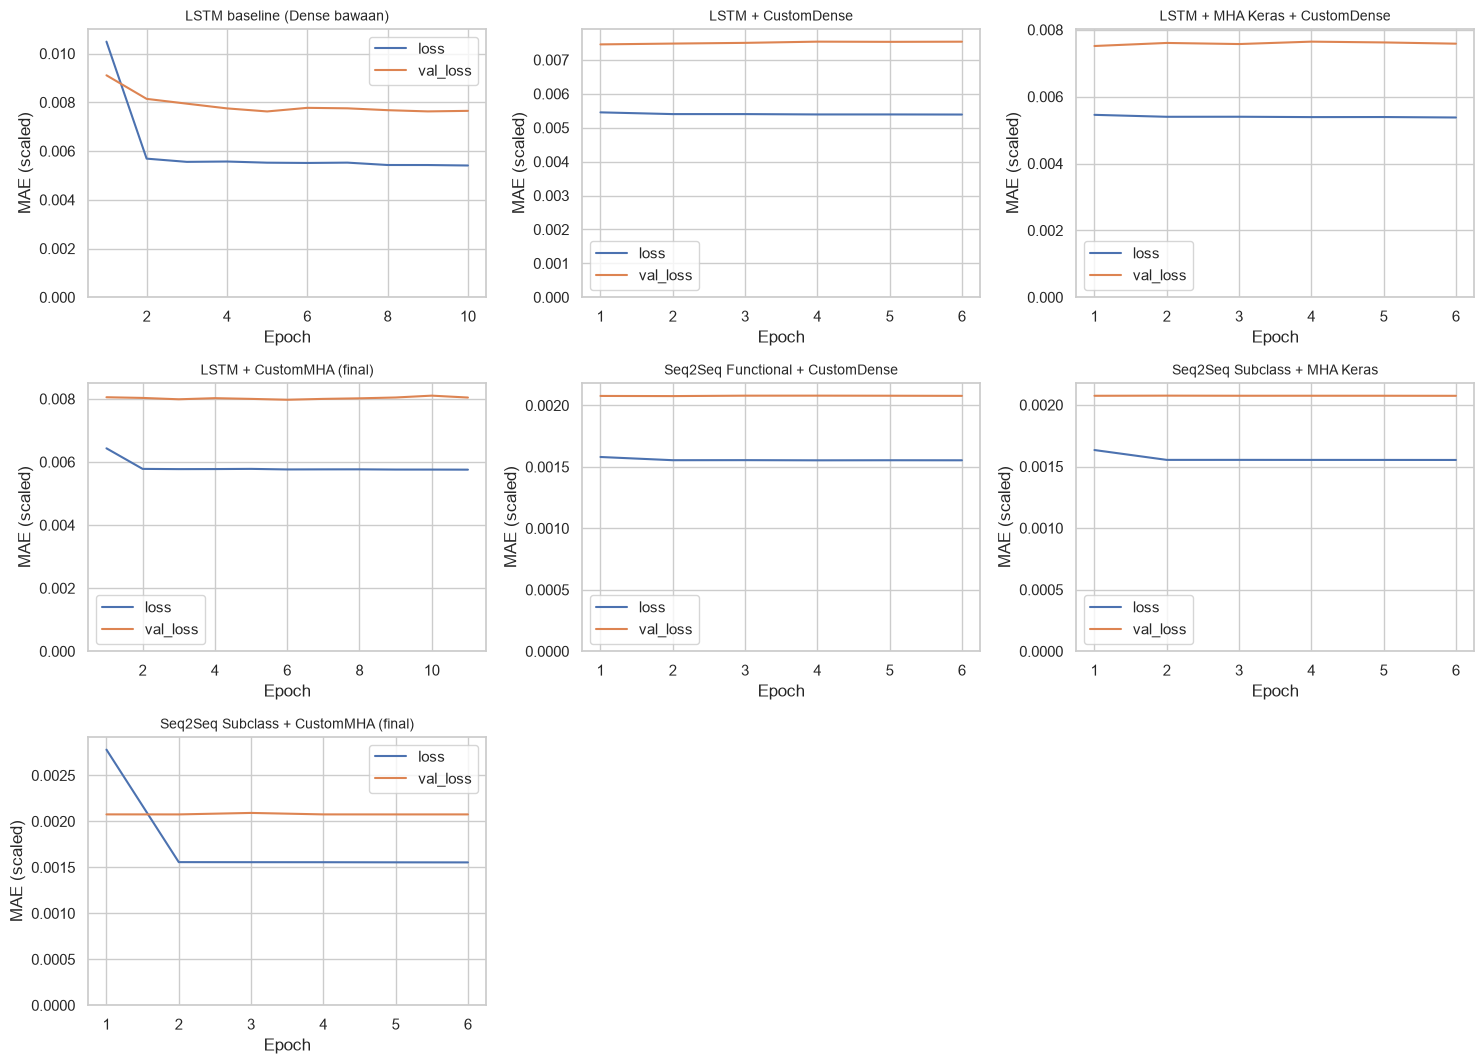

In [27]:
names = list(HISTORIES)
cols = 3
rows = math.ceil(len(names) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(15, 3.6 * rows))
for ax, nm in zip(axes.ravel(), names):
    h = HISTORIES[nm]
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], label="loss")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="val_loss")
    ax.set_title(nm, fontsize=10)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MAE (scaled)")
    ax.set_ylim(0, min(0.05, max(max(h["val_loss"]), max(h["loss"])) * 1.05))
    ax.legend()
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [28]:
summary = pd.DataFrame(RESULTS).T
summary["Test MAE (scaled)"] = summary["Test MAE (scaled)"].astype(float)
summary = summary.sort_values("Test MAE (scaled)")
display(summary.style.format({"Test MAE (scaled)": "{:.5f}", "Test RMSE (scaled)": "{:.5f}", "Test MAE (USD)": "{:,.1f}"}))

,Test MAE (scaled),Test RMSE (scaled),Test MAE (USD),Catatan
Naive (Close terakhir),0.00360,0.00603,235.4,pembanding tanpa model
LSTM + CustomMHA (final),0.00362,0.00602,236.8,model_baseline_LSTM.keras
LSTM + CustomDense,0.00364,0.00602,238.6,kriteria 2: Custom Layer Dense
Seq2Seq Subclass + CustomMHA (final),0.00366,0.00601,239.3,model_seq2seq_LSTM.keras (bobot epoch terakhir)
Seq2Seq Subclass + MHA Keras,0.00367,0.00616,240.5,kriteria 2: Subclassing + MHA
LSTM + MHA Keras + CustomDense,0.00368,0.00602,240.8,kriteria 2: Multi-Head Attention
Seq2Seq Functional + CustomDense,0.00373,0.00605,244.5,kriteria 2: Seq2Seq Functional API
LSTM baseline (Dense bawaan),0.00396,0.00634,259.5,kriteria 1: baseline
Seq2Seq Subclass + CustomMHA (best),0.00419,0.00644,274.2,best_model_seq2seq_LSTM.keras (epoch 1)


### Evaluasi Model Final

Target Advanced: MAE data test Custom Seq2Seq LSTM di bawah 0,015 (skala ternormalisasi).

MAE test model Custom Seq2Seq LSTM (scaled): 0.00366 -> memenuhi target < 0.015
MAE test model LSTM + CustomMHA        (scaled): 0.00362


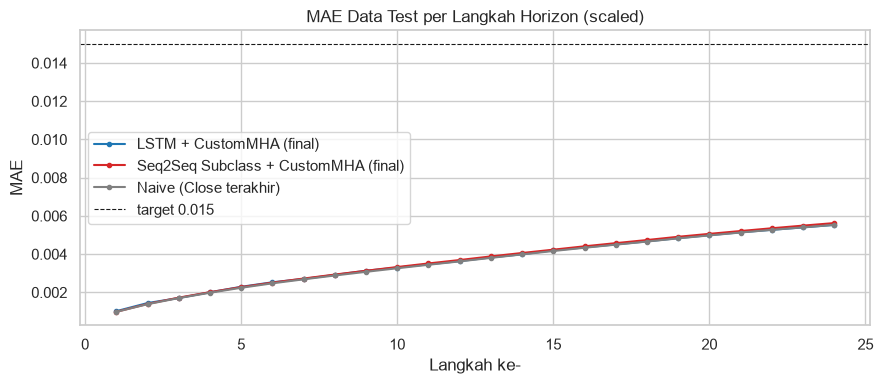

In [29]:
FINAL_LSTM, FINAL_S2S = "LSTM + CustomMHA (final)", "Seq2Seq Subclass + CustomMHA (final)"
mae_s2s = RESULTS[FINAL_S2S]["Test MAE (scaled)"]
print(f"MAE test model Custom Seq2Seq LSTM (scaled): {mae_s2s:.5f} -> {'memenuhi' if mae_s2s < 0.015 else 'BELUM memenuhi'} target < 0.015")
print(f"MAE test model LSTM + CustomMHA        (scaled): {RESULTS[FINAL_LSTM]['Test MAE (scaled)']:.5f}")

# MAE per langkah horizon
steps = np.arange(1, HORIZON + 1)
plt.figure(figsize=(9, 4))
for nm, c in [(FINAL_LSTM, "tab:blue"), (FINAL_S2S, "tab:red"), ("Naive (Close terakhir)", "gray")]:
    plt.plot(steps, np.abs(Y_test - PREDICTIONS[nm]).mean(axis=0), marker="o", ms=3, label=nm, color=c)
plt.axhline(0.015, color="k", ls="--", lw=0.8, label="target 0.015")
plt.title("MAE Data Test per Langkah Horizon (scaled)")
plt.xlabel("Langkah ke-")
plt.ylabel("MAE")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Visualisasi Prediksi

Grafik menampilkan prediksi 24 jam ke depan untuk model final: LSTM baseline dengan `CustomMultiHeadAttention` dan Seq2Seq (autoregressive), dibandingkan dengan nilai aktual pada data test.

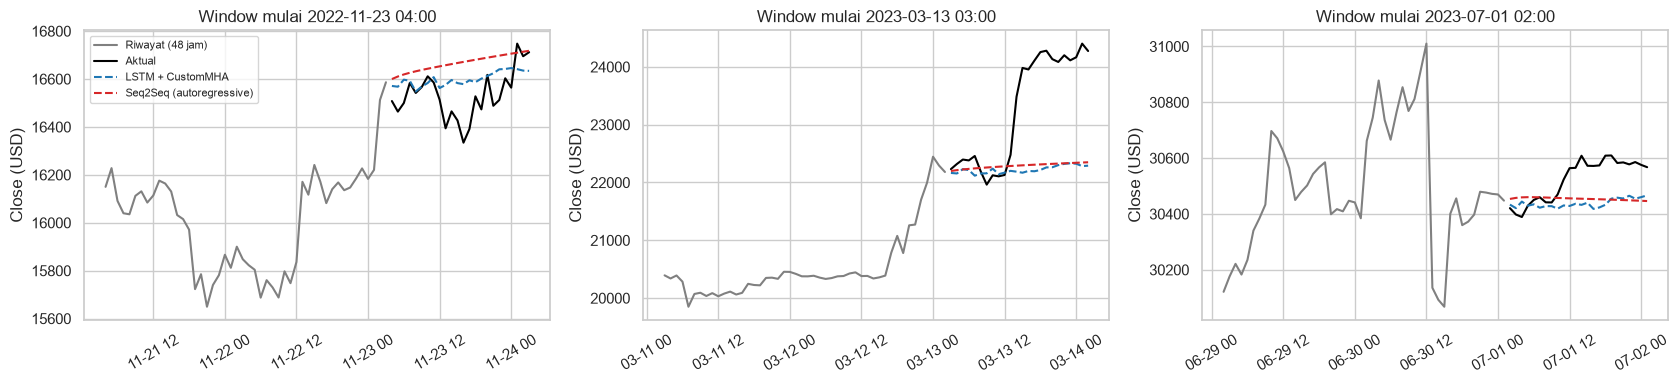

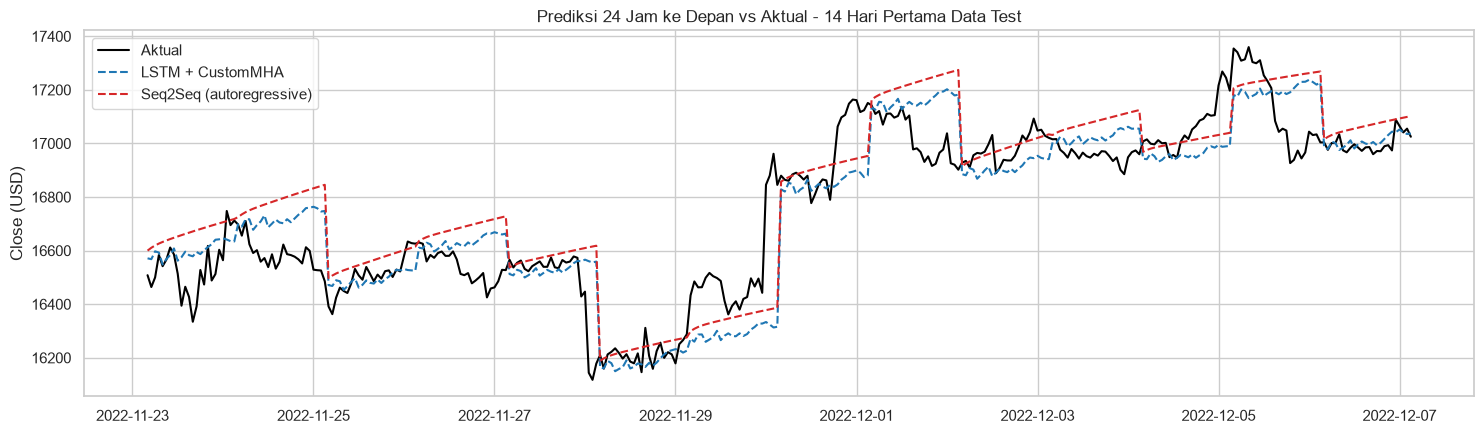

In [30]:
test_time = test_df.index
def window_times(i):
    return test_time[i + WINDOW:i + WINDOW + HORIZON]

# (a) Tiga window contoh: konteks 48 jam terakhir + 24 jam prediksi
sample_ids = [0, len(X_test) // 3, 2 * len(X_test) // 3]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, i in zip(axes, sample_ids):
    hist_t = test_time[i:i + WINDOW]
    ax.plot(hist_t, inverse_close(X_test[i, :, TARGET_IDX]), color="gray", label="Riwayat (48 jam)")
    ax.plot(window_times(i), inverse_close(Y_test[i]), color="black", label="Aktual")
    ax.plot(window_times(i), inverse_close(PREDICTIONS[FINAL_LSTM][i]), color="tab:blue", ls="--", label="LSTM + CustomMHA")
    ax.plot(window_times(i), inverse_close(PREDICTIONS[FINAL_S2S][i]), color="tab:red", ls="--", label="Seq2Seq (autoregressive)")
    ax.set_title(f"Window mulai {window_times(i)[0]:%Y-%m-%d %H:%M}")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylabel("Close (USD)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# (b) Rangkaian window 24 jam berurutan (tanpa tumpang tindih) selama 14 hari pertama data test
ids = list(range(0, 14 * 24, HORIZON))
t_cat = np.concatenate([window_times(i) for i in ids])
plt.figure(figsize=(15, 4.5))
plt.plot(t_cat, inverse_close(np.concatenate([Y_test[i] for i in ids])), color="black", label="Aktual")
plt.plot(t_cat, inverse_close(np.concatenate([PREDICTIONS[FINAL_LSTM][i] for i in ids])), color="tab:blue", ls="--", label="LSTM + CustomMHA")
plt.plot(t_cat, inverse_close(np.concatenate([PREDICTIONS[FINAL_S2S][i] for i in ids])), color="tab:red", ls="--", label="Seq2Seq (autoregressive)")
plt.title("Prediksi 24 Jam ke Depan vs Aktual - 14 Hari Pertama Data Test")
plt.ylabel("Close (USD)")
plt.legend()
plt.tight_layout()
plt.show()

### Tabel Perbandingan Aktual vs Prediksi

Satu window 24 jam pertama pada data test. Kolom selisih = aktual - prediksi (USD).

In [31]:
i = 0
tbl = pd.DataFrame({
    "Waktu": window_times(i),
    "Aktual (USD)": inverse_close(Y_test[i]),
    "Prediksi LSTM (USD)": inverse_close(PREDICTIONS[FINAL_LSTM][i]),
    "Prediksi Seq2Seq (USD)": inverse_close(PREDICTIONS[FINAL_S2S][i]),
})
tbl["Selisih LSTM"] = tbl["Aktual (USD)"] - tbl["Prediksi LSTM (USD)"]
tbl["Selisih Seq2Seq"] = tbl["Aktual (USD)"] - tbl["Prediksi Seq2Seq (USD)"]
tbl.index = np.arange(1, HORIZON + 1)
tbl.index.name = "Langkah"
display(tbl.style.format({c: "{:,.2f}" for c in tbl.columns if c != "Waktu"}))
print(f"MAE window ini | LSTM: {tbl['Selisih LSTM'].abs().mean():,.1f} USD | Seq2Seq: {tbl['Selisih Seq2Seq'].abs().mean():,.1f} USD")

,Waktu,Aktual (USD),Prediksi LSTM (USD),Prediksi Seq2Seq (USD),Selisih LSTM,Selisih Seq2Seq
Langkah,,,,,,
1,2022-11-23 04:00:00,"16,508.13","16,571.12","16,599.91",-62.99,-91.78
2,2022-11-23 05:00:00,"16,464.07","16,567.96","16,610.58",-103.88,-146.51
3,2022-11-23 06:00:00,"16,499.80","16,597.36","16,619.13",-97.56,-119.33
4,2022-11-23 07:00:00,"16,583.84","16,592.66","16,626.21",-8.82,-42.37
5,2022-11-23 08:00:00,"16,541.86","16,548.17","16,632.35",-6.31,-90.49
6,2022-11-23 09:00:00,"16,566.38","16,568.51","16,637.90",-2.13,-71.52
7,2022-11-23 10:00:00,"16,611.45","16,583.43","16,643.10",28.02,-31.65
8,2022-11-23 11:00:00,"16,585.77","16,608.00","16,648.08",-22.23,-62.31
9,2022-11-23 12:00:00,"16,513.59","16,562.43","16,652.93",-48.84,-139.34


MAE window ini | LSTM: 88.2 USD | Seq2Seq: 135.3 USD


## 10. Menyimpan Model

Model disimpan dalam format Keras (`.keras`) dan dimuat ulang untuk memastikan prediksi tetap identik.

In [32]:
m3.save("model_baseline_LSTM.keras")
s3.save("model_seq2seq_LSTM.keras")
s3_best.save("best_model_seq2seq_LSTM.keras")

for fname in ["model_baseline_LSTM.keras", "model_seq2seq_LSTM.keras", "best_model_seq2seq_LSTM.keras"]:
    print(f"{fname:<32}{os.path.getsize(fname) / 1024:>8.0f} KB")

# Verifikasi: model hasil muat ulang harus menghasilkan prediksi yang sama
re_base = keras.models.load_model("model_baseline_LSTM.keras")
re_s2s = keras.models.load_model("model_seq2seq_LSTM.keras")
re_best = keras.models.load_model("best_model_seq2seq_LSTM.keras")
d_base = np.abs(predict_direct(re_base, X_test[:512]) - PREDICTIONS[FINAL_LSTM][:512]).max()
d_s2s = np.abs(predict_autoregressive(re_s2s, X_test[:512]) - PREDICTIONS[FINAL_S2S][:512]).max()
d_best = np.abs(predict_autoregressive(re_best, X_test[:512]) - PREDICTIONS["Seq2Seq Subclass + CustomMHA (best)"][:512]).max()
print(f"Selisih prediksi setelah load ulang -> baseline: {d_base:.2e} | seq2seq: {d_s2s:.2e} | best seq2seq: {d_best:.2e}")

model_baseline_LSTM.keras            213 KB
model_seq2seq_LSTM.keras             265 KB
best_model_seq2seq_LSTM.keras        265 KB


Selisih prediksi setelah load ulang -> baseline: 0.00e+00 | seq2seq: 0.00e+00 | best seq2seq: 0.00e+00


## 11. Kesimpulan

- **Target Advanced tercapai**: MAE data test model Custom Seq2Seq LSTM (autoregressive) = **0,00366** (skala ternormalisasi, sebelum inverse scaling), jauh di bawah batas 0,015. Dalam USD, MAE rata-rata sekitar 239 USD untuk prediksi 24 jam ke depan. Model LSTM + `CustomMultiHeadAttention` mencapai 0,00362.
- Seluruh persyaratan teknis dipenuhi: 9 fitur input, heatmap korelasi, split kronologis train/validation/test, normalisasi tanpa data leakage, pipeline `tf.data`, dekomposisi, ACF/PACF (window 48 jam), rolling statistic, Seq2Seq teacher forcing (Functional API dan Subclassing), custom layer (Dense, MHA, LayerNorm, ELU, Dropout), custom training loop `tf.GradientTape`, custom loss (MAE dan MAE berbobot horizon), custom callback (early stopping dan reduce LR), serta inferensi autoregressive.
- **Catatan jujur**: pembanding naive ("harga 24 jam ke depan = Close terakhir") sudah mencapai MAE 0,00360, dan semua model berada pada kisaran 0,0036-0,0040. Harga Bitcoin per jam berperilaku mendekati *random walk* (hasil dekomposisi menunjukkan komponen musiman sangat kecil), sehingga dengan loss MAE model belajar prediksi yang mendekati persistensi. Model kustom ini belum mengungguli pembanding naive; peningkatan lebih lanjut membutuhkan sinyal tambahan (misalnya fitur on-chain atau sentimen) atau loss/target yang berbeda.
- Pada Seq2Seq final, checkpoint dengan `val_loss` terendah (epoch 1; MAE test 0,00419) tersimpan sebagai `best_model_seq2seq_LSTM.keras`, sedangkan `model_seq2seq_LSTM.keras` berisi bobot epoch terakhir (MAE test 0,00366). Selisih keduanya kecil karena kurva `val_loss` hampir datar.